# 60 · DAgger: when "fits the demonstrations" isn't enough
Behavior cloning learns from the states the *expert* visited. At deployment the robot is never exactly on that path:
actuators are sloppy, objects slide, and every small error moves it into states it has never seen. DAgger fixes this by
letting the learner drive and asking the expert what it *would* have done in every state the learner actually visits.

Two lessons, both measured:
1. **The learner must observe everything the expert's decision depends on.** Get this wrong and labels contradict each other.
2. **DAgger's value shows up when execution is imperfect**, which on a real robot is always.

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse import TableTop, ReactiveExpert, evaluate
from vlacourse.features import privileged_obs, PRIV_DIM

torch.set_num_threads(4)
# One skill (pick), so the curves are easy to read. ReactiveExpert is STATELESS: its action is a function of the current
# simulator state only, so it can label ANY state the learner wanders into. A waypoint state machine cannot.
env = TableTop(n_cubes=1, n_trays=1, task_types=("pick",), cameras=(), seed=0)

def feats_basic(env):
    """20-D: gripper pose, cube and goal relative to the ACHIEVED gripper position, yaw, task, gripper command."""
    return privileged_obs(env)

def feats_full(env):
    """+ where the arm is being COMMANDED to go, relative to where it is. The expert decides from the commanded pose;
    on the expert's own path the two differ by a constant lag, but off that path they don't."""
    return np.r_[privileged_obs(env), env.target_pos - env.state()[:3]].astype(np.float32)

def fit(X, Y, epochs=60, seed=0):
    X, Y = np.asarray(X, np.float32), np.asarray(Y, np.float32); torch.manual_seed(seed)
    st = (X.mean(0), X.std(0) + 1e-6, Y.mean(0), Y.std(0) + 1e-6)
    Xn, Yn = torch.tensor((X - st[0]) / st[1]), torch.tensor((Y - st[2]) / st[3])
    net = nn.Sequential(nn.Linear(X.shape[1], 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 7))
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    for _ in range(epochs):
        for idx in torch.randperm(len(X)).split(256):
            loss = nn.functional.mse_loss(net(Xn[idx]), Yn[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return net, st

class Learner:
    def __init__(self, env, net, st, feats):
        self.env, self.net, self.st, self.feats = env, net, st, feats
    def act(self, obs):
        with torch.no_grad():
            x = torch.tensor((self.feats(self.env) - self.st[0]) / self.st[1], dtype=torch.float32)
            a = self.net(x).numpy() * self.st[3] + self.st[2]
        a[6] = float(a[6] > 0.5); return a

def expert_demos(env, n, seed, feats):
    X, Y = [], []
    for ep in range(n):
        env.reset(seed=seed + ep); ex = ReactiveExpert(env); done = False
        while not done:
            X.append(feats(env)); a = ex.act(); Y.append(a)
            _, _, done, _ = env.step(a)
    return X, Y

def dagger_rollouts(env, learner, n, seed, beta, feats):
    """The mixture policy drives (expert with prob. beta, learner otherwise); EVERY visited state gets the expert's label."""
    rng = np.random.default_rng(seed); X, Y = [], []
    for ep in range(n):
        env.reset(seed=seed + ep); ex = ReactiveExpert(env); done = False
        while not done:
            X.append(feats(env)); a_star = ex.act(); Y.append(a_star)
            a = a_star if rng.random() < beta else learner.act(None)
            _, _, done, _ = env.step(a)
    return X, Y

SLOP = np.random.default_rng(5)
def sloppy_actuator(env, obs, a):
    """Every commanded move lands up to ~1 cm off (12 mm std): a cheap arm, a loose gear, a slipping belt."""
    a = a.copy(); a[:3] += SLOP.normal(0, 0.012, 3); return a

def score(learner, sloppy, n=60):
    return evaluate(env, learner, n_episodes=n, seed=90_000, on_step=sloppy_actuator if sloppy else None)

## Lesson 1: observe what the expert's decision depends on
Same 30 demonstrations, same network. Only the input features differ.

In [2]:
for name, feats in [("basic features (achieved pose only)", feats_basic), ("+ commanded-pose offset", feats_full)]:
    X, Y = expert_demos(env, 30, seed=0, feats=feats); net, st = fit(X, Y)
    print(f"BC on 30 demos, {name:38s} success {score(Learner(env, net, st, feats), False)['success']:.2f}")

BC on 30 demos, basic features (achieved pose only)    success 0.50


BC on 30 demos, + commanded-pose offset                success 0.93


## Lesson 2: BC vs DAgger, on a perfect arm and on a sloppy one
DAgger starts from 3 demonstrations, then runs 6 rounds of 4 learner-driven episodes, relabelled by the expert.

In [3]:
t0 = time.time(); F = feats_full
X, Y = expert_demos(env, 3, seed=0, feats=F); net, st = fit(X, Y)
dag = [(len(X), score(Learner(env, net, st, F), False)["success"], score(Learner(env, net, st, F), True)["success"])]
for it in range(6):
    beta = 0.5 ** (it + 1)
    Xd, Yd = dagger_rollouts(env, Learner(env, net, st, F), 4, seed=1000 * (it + 1), beta=beta, feats=F)
    X += Xd; Y += Yd; net, st = fit(X, Y)
    dag.append((len(X), score(Learner(env, net, st, F), False)["success"], score(Learner(env, net, st, F), True)["success"]))
    print(f"DAgger round {it + 1}: beta={beta:.3f}  labels={len(X):5d}  perfect arm {dag[-1][1]:.2f}  sloppy arm {dag[-1][2]:.2f}  ({time.time() - t0:.0f}s)")
dagger = Learner(env, net, st, F)

bc, bc_pols = [], {}
for n in [3, 8, 15, 30, 70]:
    Xb, Yb = expert_demos(env, n, seed=0, feats=F); m, s_ = fit(Xb, Yb)
    bc_pols[n] = Learner(env, m, s_, F)
    bc.append((len(Xb), score(bc_pols[n], False)["success"], score(bc_pols[n], True)["success"]))
    print(f"BC {n:3d} demos  labels={len(Xb):5d}  perfect arm {bc[-1][1]:.2f}  sloppy arm {bc[-1][2]:.2f}")

DAgger round 1: beta=0.500  labels=  132  perfect arm 0.37  sloppy arm 0.45  (98s)


DAgger round 2: beta=0.250  labels=  316  perfect arm 0.95  sloppy arm 0.98  (110s)


DAgger round 3: beta=0.125  labels=  408  perfect arm 0.63  sloppy arm 0.83  (129s)


DAgger round 4: beta=0.062  labels=  662  perfect arm 0.78  sloppy arm 0.97  (143s)


DAgger round 5: beta=0.031  labels=  910  perfect arm 0.80  sloppy arm 0.97  (156s)


DAgger round 6: beta=0.016  labels=  976  perfect arm 0.85  sloppy arm 1.00  (167s)


BC   3 demos  labels=   51  perfect arm 0.03  sloppy arm 0.07


BC   8 demos  labels=  133  perfect arm 0.45  sloppy arm 0.17


BC  15 demos  labels=  248  perfect arm 0.88  sloppy arm 0.20


BC  30 demos  labels=  500  perfect arm 0.93  sloppy arm 0.68


BC  70 demos  labels= 1166  perfect arm 1.00  sloppy arm 0.93


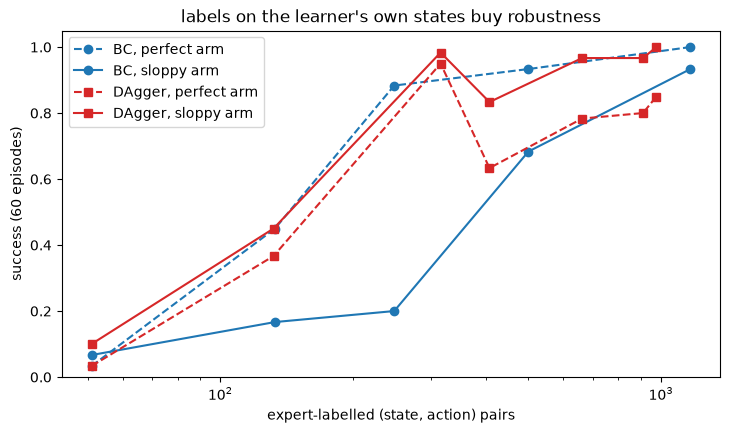

In [4]:
dag, bc = np.array(dag), np.array(bc)
plt.figure(figsize=(8.5, 4.5))
plt.plot(bc[:, 0], bc[:, 1], "o--", c="tab:blue", label="BC, perfect arm"); plt.plot(bc[:, 0], bc[:, 2], "o-", c="tab:blue", label="BC, sloppy arm")
plt.plot(dag[:, 0], dag[:, 1], "s--", c="tab:red", label="DAgger, perfect arm"); plt.plot(dag[:, 0], dag[:, 2], "s-", c="tab:red", label="DAgger, sloppy arm")
plt.xscale("log"); plt.xlabel("expert-labelled (state, action) pairs"); plt.ylabel("success (60 episodes)"); plt.ylim(0, 1.05)
plt.legend(); plt.title("labels on the learner's own states buy robustness"); plt.show()

### Watch it: BC (70 demos) vs DAgger on the sloppy arm
Same episode, same random actuator errors. BC was only ever shown the expert's clean path.

In [5]:
from vlacourse import showcase as sc
ra, rb = score(dagger, True, 30), score(bc_pols[70], True, 30)
seed = sc.pick_seed(ra, rb, 90_000)
def same_slop(env, obs, a, _r={}):
    if env.t == 0:
        _r["rng"] = np.random.default_rng(seed)                    # identical actuator errors for both runs
    a = a.copy(); a[:3] += _r["rng"].normal(0, 0.012, 3); return a
sc.compare(env, {"BC, 70 demos": bc_pols[70], f"DAgger, {int(dag[-1, 0])} labels": dagger}, seed=seed, on_step=same_slop,
           title="60 BC vs DAgger on a sloppy arm", footer="every commanded move lands ~1 cm off")

60 BC vs DAgger on a sloppy arm: BC, 70 demos: success | DAgger, 976 labels: success


[True, True]

## Exercise: DART
DART (Laskey et al. 2017) gets DAgger-like robustness without letting the learner drive: the *expert* executes noisy
actions while you record its clean labels. Implement it (copy `expert_demos`, add `a_exec[:3] += rng.normal(0, σ, 3)`
before `env.step`, keep only successful episodes) and compare with BC at σ = 5 mm on both arms.
In our runs DART helped on the sloppy arm but **collapsed on the perfect arm**. Find out why: watch a rollout and look
at where it stops. (Hint: what does the learner see right at the grasp pose, in data where noise always nudged it there?)